# 24. Как пятну не потерять своего соседа

[План курса](../../README_ru.md)

У вращающейся детали два одинаковых пятна. На очередном кадре можно заново подобрать два центра и получить красивую картинку. Но какой из новых центров принадлежит прежнему пятну? Сама картинка может этого вообще не заметить.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dynamic_motion.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import dynamic_motion as motion
from dynamic_motion_demos import motion_figure, motion_lab
lang = 'ru'

## Одна картинка, две истории

У пятен одинаковые цвет, форма и непрозрачность. Сначала центры находятся на 0.4 м слева и справа от середины. В следующем кадре они в тех же местах. Один вариант — оба стояли на месте. Другой — поменялись местами между экспозициями. Назовём левое в первом кадре пятно A, правое B. Буквы обозначают постоянные номера в массиве. Они не становятся частью изображения.

Код строит оба последних кадра тем же рендерером, что использовался для статической сцены. В одной истории A прошла 0 м, в другой $0.4-(-0.4)=0.8$ м. Разница пикселей одинакового цвета при перестановке двух вкладов остаётся нулевой с точностью вычислений.

In [2]:
from splat_render import make_scene, splat, render_scene, translated_camera
def dot(x):
    return splat([x, 0, 4], [.16, .12, .1], [.9, .3, .1], .9)
stationary, exchanged = make_scene(dot(-.4), dot(.4)), make_scene(dot(.4), dot(-.4))
frames = [render_scene(s, translated_camera(0, 80), 97, 61) for s in [stationary, exchanged]]
print('A: 0 or 0.8 m   max |ΔRGB| =', np.max(np.abs(frames[0] - frames[1])))

A: 0 or 0.8 m   max |ΔRGB| = 1.1102230246251565e-16


## Что сообщает сосед

Теперь у пятна A видна ориентация, например по вытянутой форме. A повернулась на четверть оборота. Если B сидит на той же жёсткой детали, вместе с A поворачивается и отрезок между центрами. В опыте A находится в начале координат текущего кадра. Синим обозначен конец отрезка при жёстком повороте, зелёным — истинный B, оранжевым — оценка по наблюдениям. Ползунок «Сгиб» позволяет соседу двигаться относительно детали.

In [3]:
display(motion_lab(24, lang))

## Поворот отрезка в числах

В предыдущем кадре A находилась при $(-0.4,-0.2)$ м, B при $(0.4,-0.2)$ м. Вычтем координаты A из координат B. По горизонтали $0.4-(-0.4)=0.8$ м, по вертикали $-0.2-(-0.2)=0$. Получился отрезок $(0.8,0)$. Когда A переносится в $(0,0)$, сам перенос отрезок не растягивает.

Угол поворота обозначим $\theta$. Положительная ось $y$ смотрит вниз, как на фотографии. При повороте на $90^\circ$ направление вправо сменится направлением вниз. Для произвольного угла единичное направление вправо переходит в $(\cos\theta,\sin\theta)$. Умножение каждой координаты на длину 0.8 м даёт ожидаемый конец отрезка $r$. При $\cos90^\circ=0$ и $\sin90^\circ=1$ он окажется в $r=(0,0.8)$ м.

Оранжевая отметка в текущем кадре дала $q=(0.4,0.6)$ м. Разность $q-r=(0.4,-0.2)$ м. Длина расхождения по Пифагору равна $\sqrt{0.4^2+(-0.2)^2}=\sqrt{0.20}\approx0.447$ м. Если просто поставить B в отметку, именно столько составит ошибка при настоящем жёстком повороте.

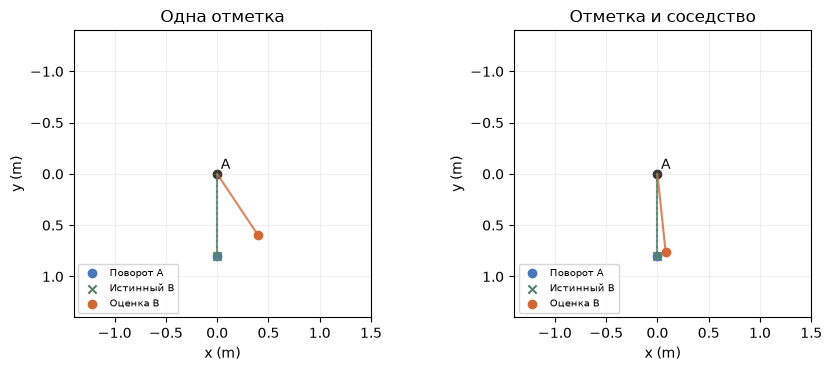

In [4]:
fig = motion_figure(24, lang, strength=4)
plt.show()

## Как совместить отметку и поворот

Возьмём пока одну координату. Буква $b$ означает пробное положение B в метрах, $q$ — измеренное, $r$ — предсказанное поворотом. Поставим рядом две квадратичные ошибки. Коэффициент $\lambda$ без единиц и неотрицателен. При $\lambda=4$ за одинаковое по длине отклонение от жёсткого соседа платим в четыре раза больше, чем за отклонение от отметки. Обе ошибки — в квадратных метрах.

$$
L(b)=(b-q)^2+\lambda(b-r)^2.
$$

Производная квадрата из урока 7 равна удвоенной разности. У суммы складываются производные. В нижней точке сумма равна нулю. Делим обе стороны на 2, собираем слагаемые с $b$ слева и выносим общий множитель.

$$
\begin{aligned}
2(b-q)+2\lambda(b-r)&=0,\\
b+\lambda b&=q+\lambda r,\\
b&=\frac{q+\lambda r}{1+\lambda}.
\end{aligned}
$$

Знаменатель положителен даже при нулевом весе. По горизонтали получаем $(0.4+4\cdot0)/5=0.08$ м. По вертикали $(0.6+4\cdot0.8)/5=0.76$ м. От жёсткого прогноза остались $(0.08,-0.04)$ м, расстояние около 0.089 м. Эта формула даёт точный минимум нашей маленькой задачи с квадратами.

In [5]:
for weight in [0, 1, 4, 10]:
    result = motion.persistent_pair(strength=weight)
    print(f"λ={weight:2d}   B={np.round(result['fitted'],3)} m   |Δ|={result['tracking_error']:.4f} m")

λ= 0   B=[0.4 0.6] m   |Δ|=0.4472 m
λ= 1   B=[0.2 0.7] m   |Δ|=0.2236 m
λ= 4   B=[0.08 0.76] m   |Δ|=0.0894 m
λ=10   B=[0.036 0.782] m   |Δ|=0.0407 m


## От одной пары к Dynamic 3D Gaussians

В работе Luiten и соавторов первый момент восстанавливается как статическая сцена по нескольким камерам. В следующие моменты у тех же гауссиан меняются центры и повороты. В описанной в статье модели размер, цвет и непрозрачность сохраняются. Изображения с камер сравниваются с рендером. Готовые траектории точек этому сравнению не требуются. [Проект и результаты авторов](https://dynamic3dgaussians.github.io/)

У каждой гауссианы авторы выбирают 20 ближайших соседей по положению в первом кадре. Чем ближе пара была изначально, тем больше её вес. Три штрафа отвечают за разные вещи. Первый сравнивает соседний отрезок между последовательными моментами с учётом поворота A — примерно это мы только что сделали с одной парой. Второй сравнивает, на сколько повернулись **сами** A и B за один шаг. Два пятна могут остаться на местах, но повернуть свои длинные оси по-разному. Третий сравнивает нынешнюю **длину** отрезка с длиной в первом кадре. Так небольшое растяжение за каждый кадр не накапливается незаметно. [Три условия соседства](https://arxiv.org/html/2308.09713v1)

В опыте уже известны поворот A и измеренные координаты B. В оригинале центры и ориентации многих пятен подбираются совместно по изображениям, с локальными ограничениями. Наш квадрат расстояния удобен тем, что даёт ответ вручную. В формуле локальной жёсткости из статьи используется длина векторного расхождения. Публичный код отдельно позволяет цвету немного меняться со штрафом за изменение. [Реализация авторов](https://github.com/JonathonLuiten/Dynamic3DGaussians/blob/main/train.py)

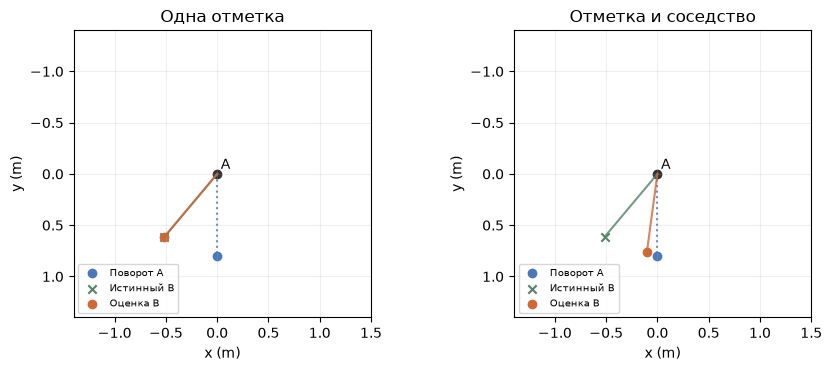

In [6]:
fig = motion_figure(24, lang, strength=4, noise=0, bend=40)
plt.show()

**У шарнира.** Отметка точна, но деталь согнулась ещё на $40^\circ$ относительно поворота A. Что даст большой вес соседства?

<details><summary>Разбор</summary>

Без шума отметка попадает в истинный B. При $\lambda=0$ оранжевая точка совпадёт с зелёной. С ростом веса она сдвинется к синему концу, который предполагает жёсткую деталь. При $\lambda=4$ исходное расхождение между двумя предсказаниями делится в отношении 4 к 1, так что оценка проходит четыре пятых пути от истинной отметки к неверному прогнозу. По разные стороны шарнира даже хорошие соседи первого кадра могут двигаться по-разному.

</details>